In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [26]:
import torch.nn.functional as F

class Conv3LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(Conv3LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.input_size = input_size
        
        # Define convolutional layers
        self.conv1 = nn.Conv1d(input_size, 64, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv1d(128, 256, kernel_size=3, stride=1, padding=1)
        
        # Define LSTM layer
        self.lstm = nn.LSTM(256, hidden_size, num_layers, batch_first=True)
        
        # Define fully connected layers
        self.fc1 = nn.Linear(hidden_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        batch_size = x.size(0)

        # Apply convolutional layers
        x = x.permute(0, 2, 1)  # Conv1d expects input in (batch, channels, length) format
        x = self.relu(self.conv1(x))
        x = F.avg_pool1d(x, kernel_size=1)  # Use average pooling instead of max pooling
        x = self.relu(self.conv2(x))
        x = F.avg_pool1d(x, kernel_size=1)  # Use average pooling instead of max pooling
        x = self.relu(self.conv3(x))
        x = F.avg_pool1d(x, kernel_size=1)  # Use average pooling instead of max pooling

        # Reshape the output of convolutional layers
        x = x.permute(0, 2, 1)  # Reshape back to (batch, length, channels)

        # LSTM layer
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        out, _ = self.lstm(x, (h0, c0))

        # Apply fully connected layers
        out = self.relu(out[:, -1, :])  # Consider only the output of the last time step
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.softmax(out)

        return out


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [15]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    X = np.expand_dims(X, -1)
    X = np.moveaxis(X, 1, -1)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = mfcc*(dwt_level +1)
    hidden_size = 256
    num_layers = 1

        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = Conv3LSTMModel(input_size, hidden_size, num_layers, num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(f'Input Size : {input_size}\n'
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [16]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [17]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [18]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# SAVEE

# dwt 5-
# n_mfcc 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  5
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 5 = 240
Training with DWT level: 5
Input Size : 240
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (480, 1, 240)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7621, Training Accuracy: 0.2812, Training Precision:0.1293,Training Recall:0.2812,Training F1-Score:0.1596
Validation Loss: 1.6805, Validation Accuracy: 0.3958, Validation Precision:0.2269,Validation Recall:0.3958,Validation F1-Score:0.2666
Epoch [2/500],
Training Loss: 1.7034, Training Accuracy: 0.3906, Training Precision:0.1851,Training Recall:0.3906,Training F1-Score:0.2512
Validation Loss: 1.6138, Validation Accuracy: 0.4583, Validation Precision:0.2689,Validation Recall:0.4583,Validation F1-Score:0.3387
Epoch [3/500],
Training Loss: 1.6461, Training Accuracy: 0.4271, Training Precision:0.2799,Training Recall:0.4271,Training F1-Sc

Epoch [31/500],
Training Loss: 1.3267, Training Accuracy: 0.7318, Training Precision:0.6706,Training Recall:0.7318,Training F1-Score:0.6858
Validation Loss: 1.4074, Validation Accuracy: 0.6354, Validation Precision:0.6144,Validation Recall:0.6354,Validation F1-Score:0.5804
Epoch [32/500],
Training Loss: 1.3299, Training Accuracy: 0.7214, Training Precision:0.6777,Training Recall:0.7214,Training F1-Score:0.6815
Validation Loss: 1.4126, Validation Accuracy: 0.6354, Validation Precision:0.6341,Validation Recall:0.6354,Validation F1-Score:0.5885
Epoch [33/500],
Training Loss: 1.3307, Training Accuracy: 0.7161, Training Precision:0.6683,Training Recall:0.7161,Training F1-Score:0.6730
Validation Loss: 1.3988, Validation Accuracy: 0.6458, Validation Precision:0.5977,Validation Recall:0.6458,Validation F1-Score:0.5788
Epoch [34/500],
Training Loss: 1.3240, Training Accuracy: 0.7266, Training Precision:0.6837,Training Recall:0.7266,Training F1-Score:0.6870
Validation Loss: 1.4271, Validation Ac

Epoch [61/500],
Training Loss: 1.3152, Training Accuracy: 0.7292, Training Precision:0.6560,Training Recall:0.7292,Training F1-Score:0.6811
Validation Loss: 1.4006, Validation Accuracy: 0.6250, Validation Precision:0.5383,Validation Recall:0.6250,Validation F1-Score:0.5716
Epoch [62/500],
Training Loss: 1.3115, Training Accuracy: 0.7422, Training Precision:0.6711,Training Recall:0.7422,Training F1-Score:0.6945
Validation Loss: 1.4112, Validation Accuracy: 0.6250, Validation Precision:0.5734,Validation Recall:0.6250,Validation F1-Score:0.5750
Epoch [63/500],
Training Loss: 1.2988, Training Accuracy: 0.7448, Training Precision:0.6675,Training Recall:0.7448,Training F1-Score:0.6948
Validation Loss: 1.3692, Validation Accuracy: 0.6771, Validation Precision:0.5897,Validation Recall:0.6771,Validation F1-Score:0.6239
Epoch [64/500],
Training Loss: 1.3088, Training Accuracy: 0.7292, Training Precision:0.6725,Training Recall:0.7292,Training F1-Score:0.6829
Validation Loss: 1.4061, Validation Ac

Epoch [91/500],
Training Loss: 1.2406, Training Accuracy: 0.8255, Training Precision:0.8355,Training Recall:0.8255,Training F1-Score:0.8227
Validation Loss: 1.3475, Validation Accuracy: 0.6979, Validation Precision:0.7060,Validation Recall:0.6979,Validation F1-Score:0.6848
Epoch [92/500],
Training Loss: 1.2178, Training Accuracy: 0.8073, Training Precision:0.8339,Training Recall:0.8073,Training F1-Score:0.8000
Validation Loss: 1.3555, Validation Accuracy: 0.6771, Validation Precision:0.6984,Validation Recall:0.6771,Validation F1-Score:0.6656
Epoch [93/500],
Training Loss: 1.2157, Training Accuracy: 0.8255, Training Precision:0.8358,Training Recall:0.8255,Training F1-Score:0.8205
Validation Loss: 1.3515, Validation Accuracy: 0.6771, Validation Precision:0.7246,Validation Recall:0.6771,Validation F1-Score:0.6554
Epoch [94/500],
Training Loss: 1.2306, Training Accuracy: 0.8177, Training Precision:0.8480,Training Recall:0.8177,Training F1-Score:0.8216
Validation Loss: 1.3845, Validation Ac

Epoch [121/500],
Training Loss: 1.2315, Training Accuracy: 0.8255, Training Precision:0.8537,Training Recall:0.8255,Training F1-Score:0.8188
Validation Loss: 1.3890, Validation Accuracy: 0.6667, Validation Precision:0.6728,Validation Recall:0.6667,Validation F1-Score:0.6521
Epoch [122/500],
Training Loss: 1.2052, Training Accuracy: 0.8568, Training Precision:0.8647,Training Recall:0.8568,Training F1-Score:0.8554
Validation Loss: 1.4162, Validation Accuracy: 0.6250, Validation Precision:0.6361,Validation Recall:0.6250,Validation F1-Score:0.6205
Epoch [123/500],
Training Loss: 1.1843, Training Accuracy: 0.8464, Training Precision:0.8624,Training Recall:0.8464,Training F1-Score:0.8437
Validation Loss: 1.3986, Validation Accuracy: 0.6458, Validation Precision:0.6876,Validation Recall:0.6458,Validation F1-Score:0.6225
Epoch [124/500],
Training Loss: 1.1801, Training Accuracy: 0.8464, Training Precision:0.8632,Training Recall:0.8464,Training F1-Score:0.8459
Validation Loss: 1.3705, Validatio

...

Epoch [361/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [362/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [363/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [364/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3653, Validatio

Epoch [391/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3653, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [392/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3653, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [393/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3653, Validation Accuracy: 0.6771, Validation Precision:0.6957,Validation Recall:0.6771,Validation F1-Score:0.6721
Epoch [394/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3653, Validatio

Epoch [421/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6896,Validation Recall:0.6771,Validation F1-Score:0.6704
Epoch [422/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6896,Validation Recall:0.6771,Validation F1-Score:0.6704
Epoch [423/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validation Accuracy: 0.6771, Validation Precision:0.6896,Validation Recall:0.6771,Validation F1-Score:0.6704
Epoch [424/500],
Training Loss: 1.0774, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.3652, Validatio

Epoch [451/500],
Training Loss: 1.1028, Training Accuracy: 0.9505, Training Precision:0.9543,Training Recall:0.9505,Training F1-Score:0.9503
Validation Loss: 1.3559, Validation Accuracy: 0.6771, Validation Precision:0.6910,Validation Recall:0.6771,Validation F1-Score:0.6757
Epoch [452/500],
Training Loss: 1.0853, Training Accuracy: 0.9297, Training Precision:0.9343,Training Recall:0.9297,Training F1-Score:0.9291
Validation Loss: 1.3568, Validation Accuracy: 0.6771, Validation Precision:0.6958,Validation Recall:0.6771,Validation F1-Score:0.6719
Epoch [453/500],
Training Loss: 1.1056, Training Accuracy: 0.9505, Training Precision:0.9540,Training Recall:0.9505,Training F1-Score:0.9506
Validation Loss: 1.3990, Validation Accuracy: 0.6354, Validation Precision:0.6814,Validation Recall:0.6354,Validation F1-Score:0.6416
Epoch [454/500],
Training Loss: 1.1004, Training Accuracy: 0.9531, Training Precision:0.9572,Training Recall:0.9531,Training F1-Score:0.9533
Validation Loss: 1.3608, Validatio

Epoch [481/500],
Training Loss: 1.2149, Training Accuracy: 0.8750, Training Precision:0.8827,Training Recall:0.8750,Training F1-Score:0.8729
Validation Loss: 1.3561, Validation Accuracy: 0.6875, Validation Precision:0.6820,Validation Recall:0.6875,Validation F1-Score:0.6733
Epoch [482/500],
Training Loss: 1.1763, Training Accuracy: 0.8464, Training Precision:0.8675,Training Recall:0.8464,Training F1-Score:0.8430
Validation Loss: 1.3282, Validation Accuracy: 0.7188, Validation Precision:0.7618,Validation Recall:0.7188,Validation F1-Score:0.6917
Epoch [483/500],
Training Loss: 1.2033, Training Accuracy: 0.8568, Training Precision:0.8759,Training Recall:0.8568,Training F1-Score:0.8544
Validation Loss: 1.3895, Validation Accuracy: 0.6562, Validation Precision:0.6860,Validation Recall:0.6562,Validation F1-Score:0.6392
Epoch [484/500],
Training Loss: 1.1814, Training Accuracy: 0.8724, Training Precision:0.8860,Training Recall:0.8724,Training F1-Score:0.8697
Validation Loss: 1.3463, Validatio

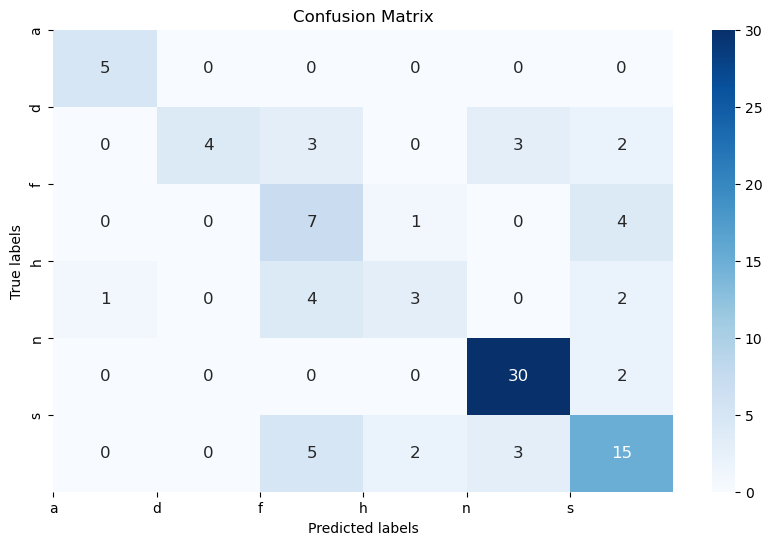

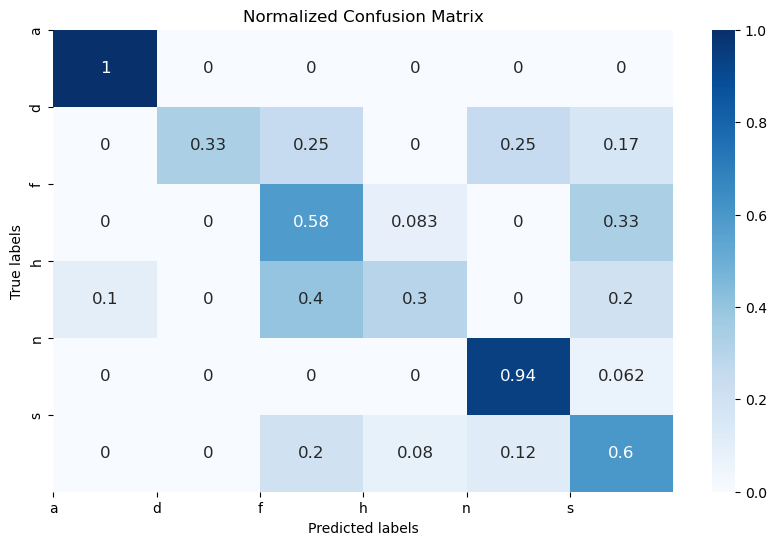

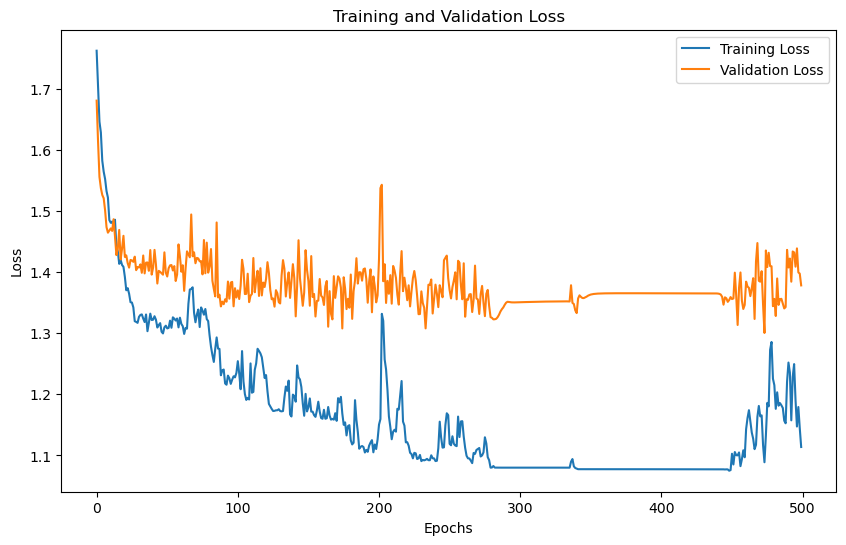

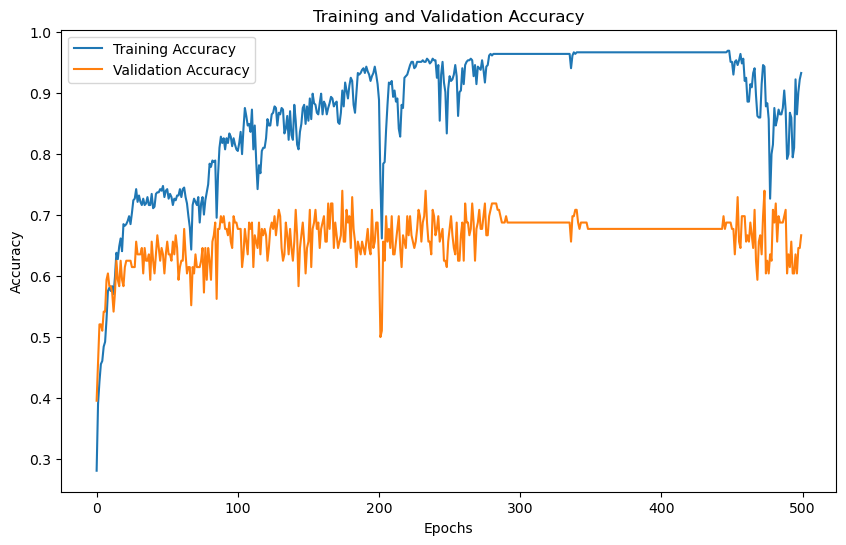

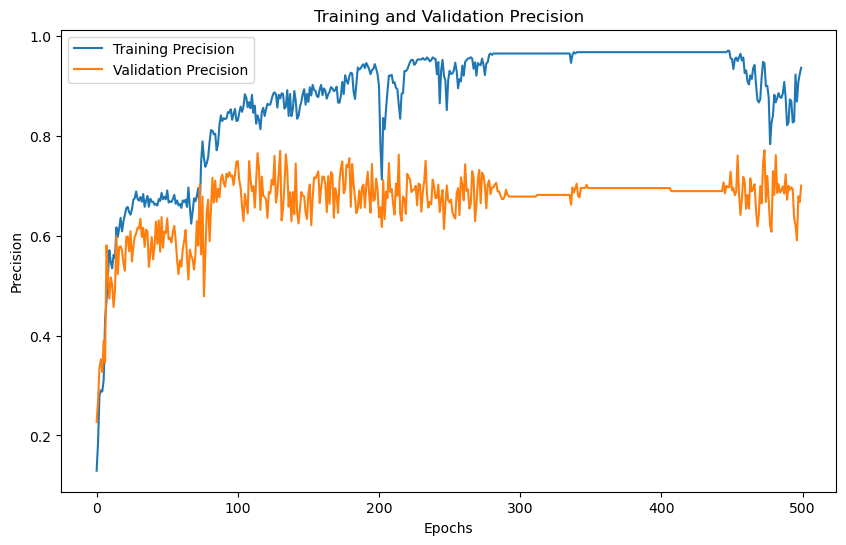

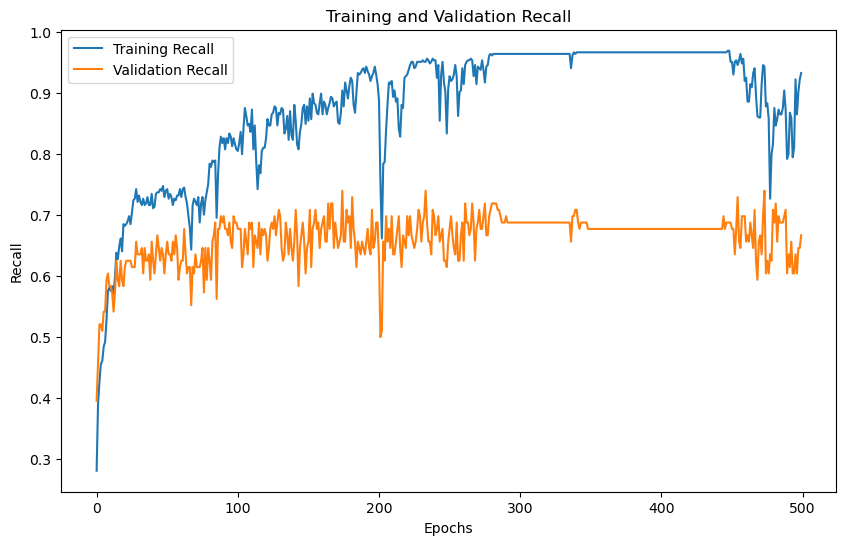

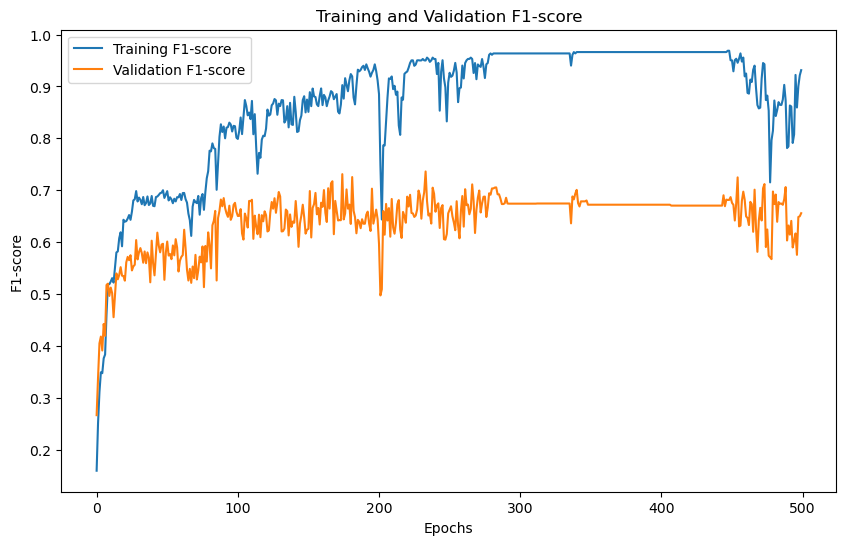

'Model Training and Evaluation Successfully completed'

In [31]:
train_model()

# SAVEE

# dwt 1
# n_mfcc 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 16
No. of classes 6
Input size for wavelet level 1 = 32
Training with DWT level: 1
Input Size : 32
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (480, 1, 32)
Y Shape : (480, 6)

Enter no. of epochs 10
Epoch [1/10],
Training Loss: 1.7865, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7689, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/10],
Training Loss: 1.7661, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7449, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [3/10],
Training Loss: 1.7419, Training Accuracy: 0.3151, Training Precision:0.1643,Training Recall:0.3151,Training F1-Score:0.2

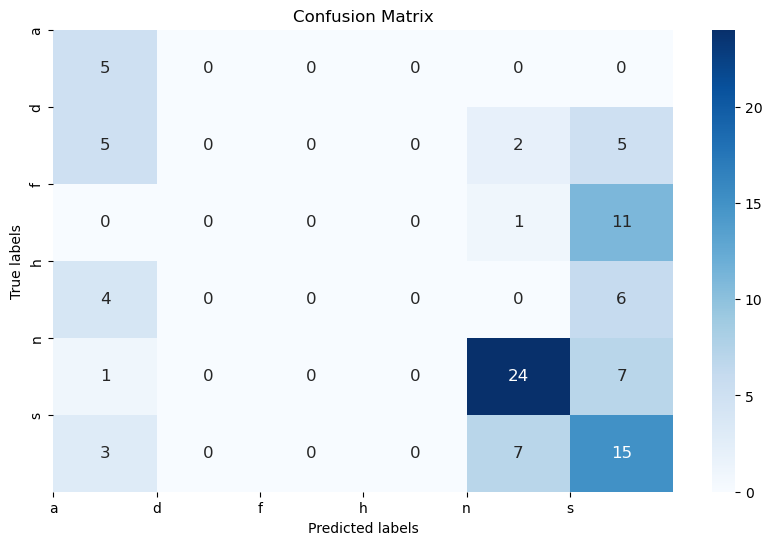

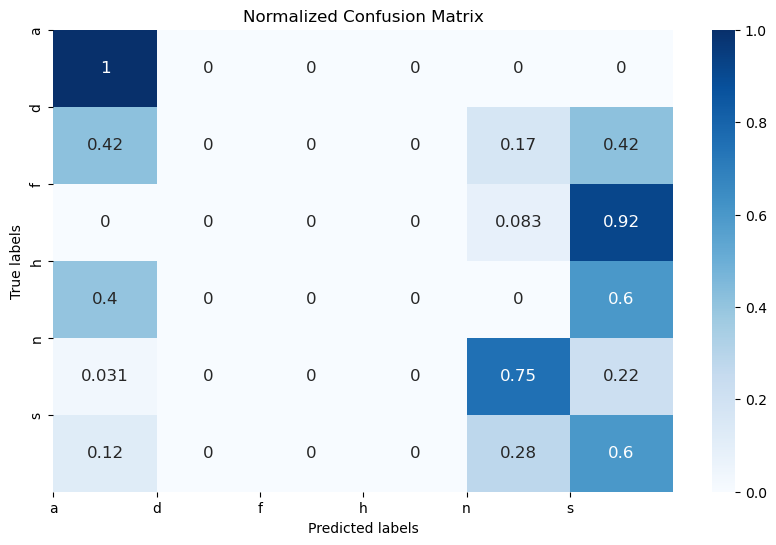

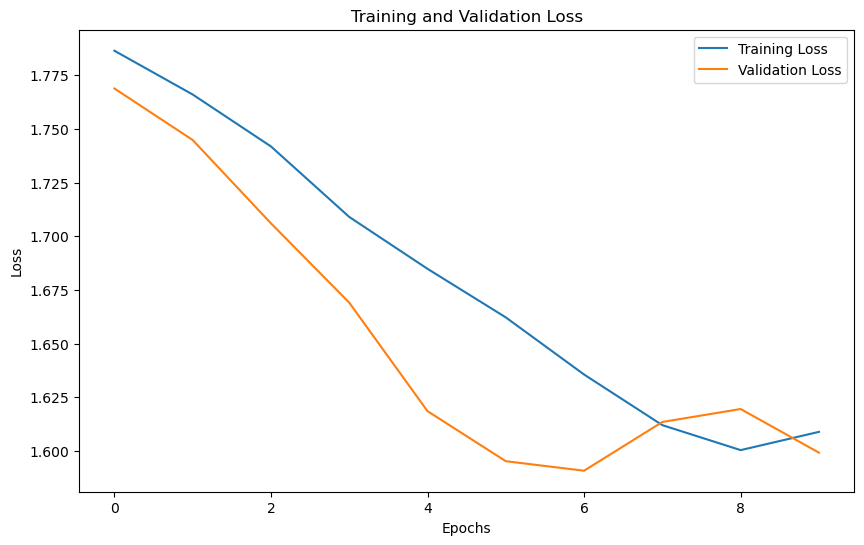

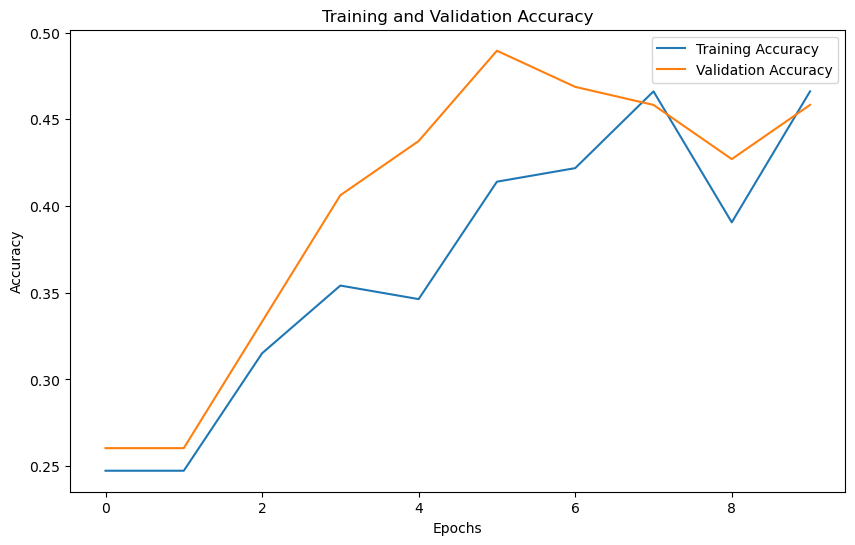

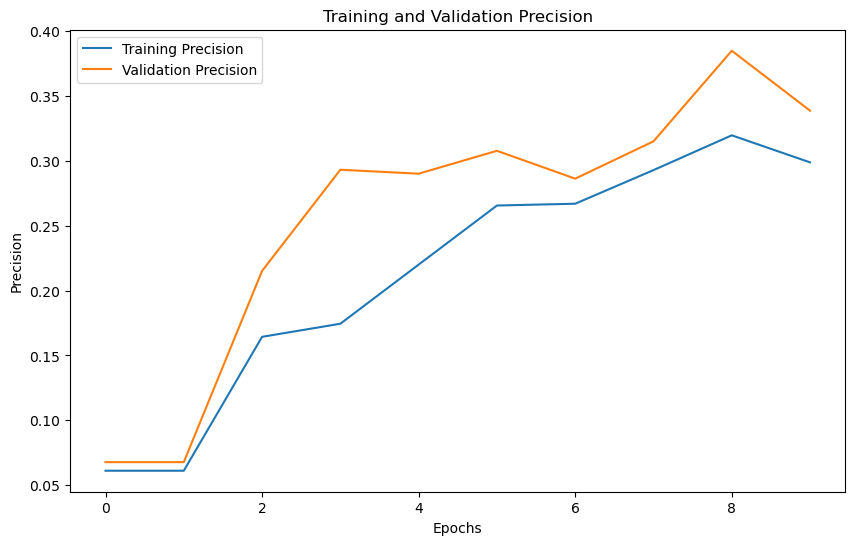

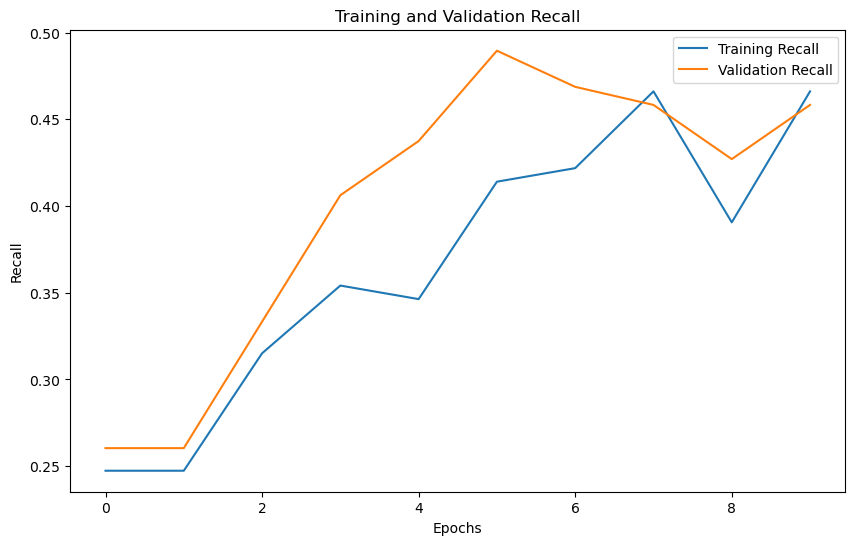

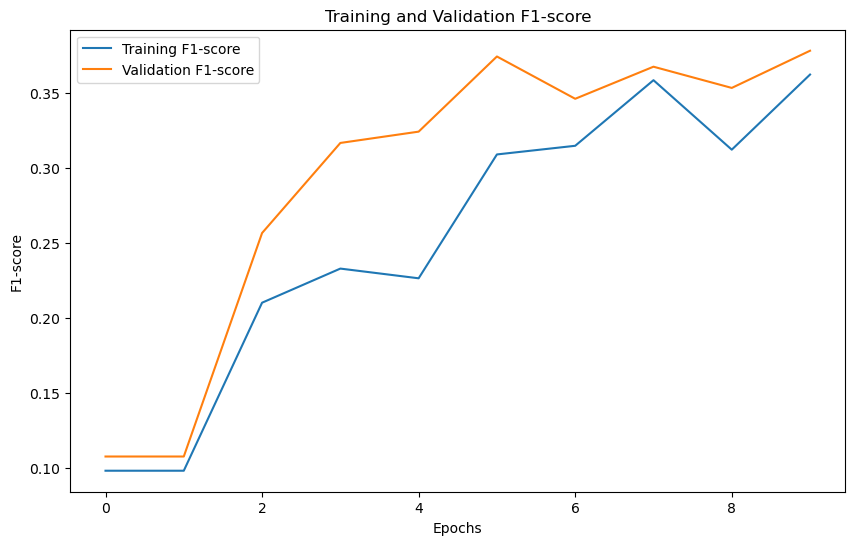

'Model Training and Evaluation Successfully completed'

In [27]:
train_model()

# Ravdess
# dwt level 2
# n_mfcc 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  2
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 2 = 72
Training with DWT level: 2
Input Size : 72
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (1440, 1, 72)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0750, Training Accuracy: 0.1389, Training Precision:0.0193,Training Recall:0.1389,Training F1-Score:0.0339
Validation Loss: 2.0719, Validation Accuracy: 0.1111, Validation Precision:0.0123,Validation Recall:0.1111,Validation F1-Score:0.0222
Epoch [2/500],
Training Loss: 2.0617, Training Accuracy: 0.2135, Training Precision:0.0566,Training Recall:0.2135,Training F1-Score:0.0893
Validation Loss: 2.0373, Validation Accuracy: 0.2292, Validation Precision:0.0603,Validation Recall:0.2292,Validation F1-Score:0.0954
Epoch [3/500],
Training Loss: 2.0311, Training Accuracy: 0.2387, Training Precision:0.1321,Training Recall:0.2387,Training F1-S

Epoch [30/500],
Training Loss: 1.8598, Training Accuracy: 0.3854, Training Precision:0.3017,Training Recall:0.3854,Training F1-Score:0.3176
Validation Loss: 1.8900, Validation Accuracy: 0.3819, Validation Precision:0.2960,Validation Recall:0.3819,Validation F1-Score:0.3215
Epoch [31/500],
Training Loss: 1.8869, Training Accuracy: 0.3663, Training Precision:0.2895,Training Recall:0.3663,Training F1-Score:0.3075
Validation Loss: 1.9168, Validation Accuracy: 0.3438, Validation Precision:0.2890,Validation Recall:0.3438,Validation F1-Score:0.2943
Epoch [32/500],
Training Loss: 1.8537, Training Accuracy: 0.4462, Training Precision:0.3568,Training Recall:0.4462,Training F1-Score:0.3746
Validation Loss: 1.8365, Validation Accuracy: 0.4410, Validation Precision:0.3420,Validation Recall:0.4410,Validation F1-Score:0.3676
Epoch [33/500],
Training Loss: 1.8375, Training Accuracy: 0.4418, Training Precision:0.3901,Training Recall:0.4418,Training F1-Score:0.3881
Validation Loss: 1.8373, Validation Ac

Epoch [60/500],
Training Loss: 1.8063, Training Accuracy: 0.4939, Training Precision:0.4273,Training Recall:0.4939,Training F1-Score:0.4268
Validation Loss: 1.8104, Validation Accuracy: 0.4583, Validation Precision:0.3568,Validation Recall:0.4583,Validation F1-Score:0.3856
Epoch [61/500],
Training Loss: 1.8198, Training Accuracy: 0.4479, Training Precision:0.4413,Training Recall:0.4479,Training F1-Score:0.3904
Validation Loss: 1.8471, Validation Accuracy: 0.4271, Validation Precision:0.3961,Validation Recall:0.4271,Validation F1-Score:0.3684
Epoch [62/500],
Training Loss: 1.8706, Training Accuracy: 0.4071, Training Precision:0.2844,Training Recall:0.4071,Training F1-Score:0.3209
Validation Loss: 1.8736, Validation Accuracy: 0.3958, Validation Precision:0.3149,Validation Recall:0.3958,Validation F1-Score:0.3213
Epoch [63/500],
Training Loss: 1.8306, Training Accuracy: 0.4566, Training Precision:0.3542,Training Recall:0.4566,Training F1-Score:0.3704
Validation Loss: 1.8282, Validation Ac

Epoch [90/500],
Training Loss: 1.7721, Training Accuracy: 0.5503, Training Precision:0.4687,Training Recall:0.5503,Training F1-Score:0.4938
Validation Loss: 1.8182, Validation Accuracy: 0.4549, Validation Precision:0.3766,Validation Recall:0.4549,Validation F1-Score:0.4031
Epoch [91/500],
Training Loss: 1.8207, Training Accuracy: 0.4696, Training Precision:0.4797,Training Recall:0.4696,Training F1-Score:0.4112
Validation Loss: 1.8211, Validation Accuracy: 0.4479, Validation Precision:0.4055,Validation Recall:0.4479,Validation F1-Score:0.3820
Epoch [92/500],
Training Loss: 1.7861, Training Accuracy: 0.5382, Training Precision:0.4375,Training Recall:0.5382,Training F1-Score:0.4758
Validation Loss: 1.8451, Validation Accuracy: 0.4201, Validation Precision:0.3386,Validation Recall:0.4201,Validation F1-Score:0.3707
Epoch [93/500],
Training Loss: 1.7482, Training Accuracy: 0.5104, Training Precision:0.4692,Training Recall:0.5104,Training F1-Score:0.4556
Validation Loss: 1.8220, Validation Ac

Epoch [120/500],
Training Loss: 1.7832, Training Accuracy: 0.5599, Training Precision:0.4988,Training Recall:0.5599,Training F1-Score:0.5017
Validation Loss: 1.8369, Validation Accuracy: 0.4340, Validation Precision:0.3654,Validation Recall:0.4340,Validation F1-Score:0.3878
Epoch [121/500],
Training Loss: 1.7230, Training Accuracy: 0.5816, Training Precision:0.5352,Training Recall:0.5816,Training F1-Score:0.5263
Validation Loss: 1.8247, Validation Accuracy: 0.4410, Validation Precision:0.3803,Validation Recall:0.4410,Validation F1-Score:0.3941
Epoch [122/500],
Training Loss: 1.7453, Training Accuracy: 0.5061, Training Precision:0.4517,Training Recall:0.5061,Training F1-Score:0.4387
Validation Loss: 1.8462, Validation Accuracy: 0.4236, Validation Precision:0.5068,Validation Recall:0.4236,Validation F1-Score:0.3587
Epoch [123/500],
Training Loss: 1.7854, Training Accuracy: 0.5339, Training Precision:0.4533,Training Recall:0.5339,Training F1-Score:0.4739
Validation Loss: 1.8530, Validatio

...

Epoch [360/500],
Training Loss: 1.4854, Training Accuracy: 0.7474, Training Precision:0.7617,Training Recall:0.7474,Training F1-Score:0.7475
Validation Loss: 1.8203, Validation Accuracy: 0.4479, Validation Precision:0.5025,Validation Recall:0.4479,Validation F1-Score:0.4463
Epoch [361/500],
Training Loss: 1.5117, Training Accuracy: 0.7135, Training Precision:0.7141,Training Recall:0.7135,Training F1-Score:0.7018
Validation Loss: 1.8657, Validation Accuracy: 0.4028, Validation Precision:0.3944,Validation Recall:0.4028,Validation F1-Score:0.3876
Epoch [362/500],
Training Loss: 1.5219, Training Accuracy: 0.7509, Training Precision:0.7539,Training Recall:0.7509,Training F1-Score:0.7400
Validation Loss: 1.8248, Validation Accuracy: 0.4514, Validation Precision:0.4752,Validation Recall:0.4514,Validation F1-Score:0.4430
Epoch [363/500],
Training Loss: 1.4844, Training Accuracy: 0.8273, Training Precision:0.8353,Training Recall:0.8273,Training F1-Score:0.8256
Validation Loss: 1.7896, Validatio

Epoch [390/500],
Training Loss: 1.4188, Training Accuracy: 0.8628, Training Precision:0.8648,Training Recall:0.8628,Training F1-Score:0.8627
Validation Loss: 1.8056, Validation Accuracy: 0.4618, Validation Precision:0.4767,Validation Recall:0.4618,Validation F1-Score:0.4664
Epoch [391/500],
Training Loss: 1.4106, Training Accuracy: 0.8767, Training Precision:0.8793,Training Recall:0.8767,Training F1-Score:0.8764
Validation Loss: 1.7613, Validation Accuracy: 0.5069, Validation Precision:0.5259,Validation Recall:0.5069,Validation F1-Score:0.5070
Epoch [392/500],
Training Loss: 1.3955, Training Accuracy: 0.8802, Training Precision:0.8830,Training Recall:0.8802,Training F1-Score:0.8797
Validation Loss: 1.7623, Validation Accuracy: 0.5069, Validation Precision:0.5254,Validation Recall:0.5069,Validation F1-Score:0.5052
Epoch [393/500],
Training Loss: 1.4043, Training Accuracy: 0.8438, Training Precision:0.8534,Training Recall:0.8438,Training F1-Score:0.8430
Validation Loss: 1.8049, Validatio

Epoch [420/500],
Training Loss: 1.3838, Training Accuracy: 0.8984, Training Precision:0.9006,Training Recall:0.8984,Training F1-Score:0.8990
Validation Loss: 1.7758, Validation Accuracy: 0.5000, Validation Precision:0.5263,Validation Recall:0.5000,Validation F1-Score:0.4992
Epoch [421/500],
Training Loss: 1.3806, Training Accuracy: 0.8958, Training Precision:0.8986,Training Recall:0.8958,Training F1-Score:0.8955
Validation Loss: 1.7355, Validation Accuracy: 0.5347, Validation Precision:0.5551,Validation Recall:0.5347,Validation F1-Score:0.5350
Epoch [422/500],
Training Loss: 1.3795, Training Accuracy: 0.9010, Training Precision:0.9027,Training Recall:0.9010,Training F1-Score:0.9010
Validation Loss: 1.7742, Validation Accuracy: 0.4965, Validation Precision:0.5279,Validation Recall:0.4965,Validation F1-Score:0.5022
Epoch [423/500],
Training Loss: 1.3821, Training Accuracy: 0.8950, Training Precision:0.8971,Training Recall:0.8950,Training F1-Score:0.8951
Validation Loss: 1.7603, Validatio

Epoch [450/500],
Training Loss: 1.3550, Training Accuracy: 0.9193, Training Precision:0.9201,Training Recall:0.9193,Training F1-Score:0.9191
Validation Loss: 1.7695, Validation Accuracy: 0.5035, Validation Precision:0.5240,Validation Recall:0.5035,Validation F1-Score:0.5013
Epoch [451/500],
Training Loss: 1.3595, Training Accuracy: 0.9193, Training Precision:0.9200,Training Recall:0.9193,Training F1-Score:0.9191
Validation Loss: 1.7911, Validation Accuracy: 0.4792, Validation Precision:0.4991,Validation Recall:0.4792,Validation F1-Score:0.4827
Epoch [452/500],
Training Loss: 1.3660, Training Accuracy: 0.9115, Training Precision:0.9135,Training Recall:0.9115,Training F1-Score:0.9115
Validation Loss: 1.7870, Validation Accuracy: 0.4722, Validation Precision:0.4948,Validation Recall:0.4722,Validation F1-Score:0.4752
Epoch [453/500],
Training Loss: 1.3657, Training Accuracy: 0.9019, Training Precision:0.9063,Training Recall:0.9019,Training F1-Score:0.9025
Validation Loss: 1.7703, Validatio

Epoch [480/500],
Training Loss: 1.3740, Training Accuracy: 0.9036, Training Precision:0.9055,Training Recall:0.9036,Training F1-Score:0.9037
Validation Loss: 1.7557, Validation Accuracy: 0.5139, Validation Precision:0.5285,Validation Recall:0.5139,Validation F1-Score:0.5126
Epoch [481/500],
Training Loss: 1.3777, Training Accuracy: 0.8932, Training Precision:0.8959,Training Recall:0.8932,Training F1-Score:0.8937
Validation Loss: 1.8067, Validation Accuracy: 0.4688, Validation Precision:0.4786,Validation Recall:0.4688,Validation F1-Score:0.4652
Epoch [482/500],
Training Loss: 1.3902, Training Accuracy: 0.8932, Training Precision:0.8944,Training Recall:0.8932,Training F1-Score:0.8934
Validation Loss: 1.7875, Validation Accuracy: 0.4792, Validation Precision:0.4742,Validation Recall:0.4792,Validation F1-Score:0.4716
Epoch [483/500],
Training Loss: 1.3869, Training Accuracy: 0.8854, Training Precision:0.8908,Training Recall:0.8854,Training F1-Score:0.8847
Validation Loss: 1.7700, Validatio

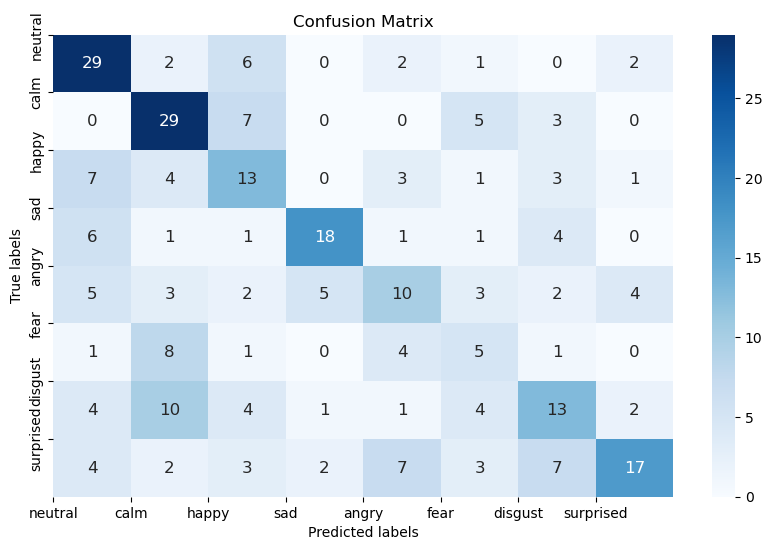

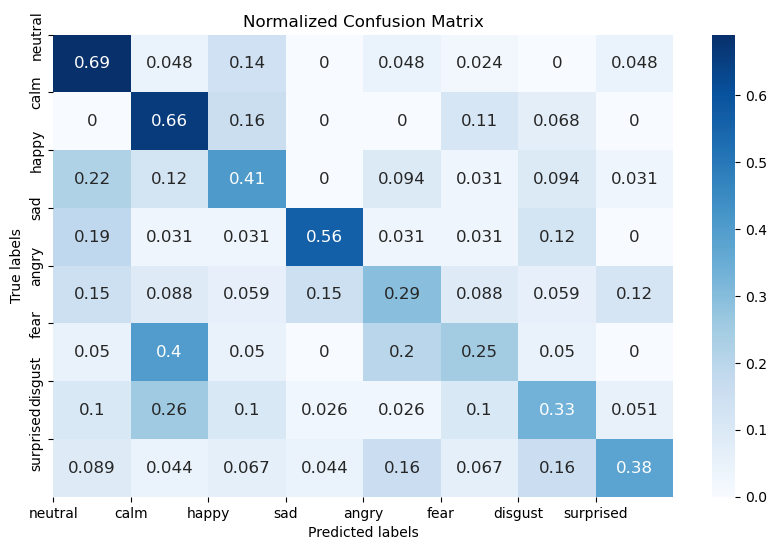

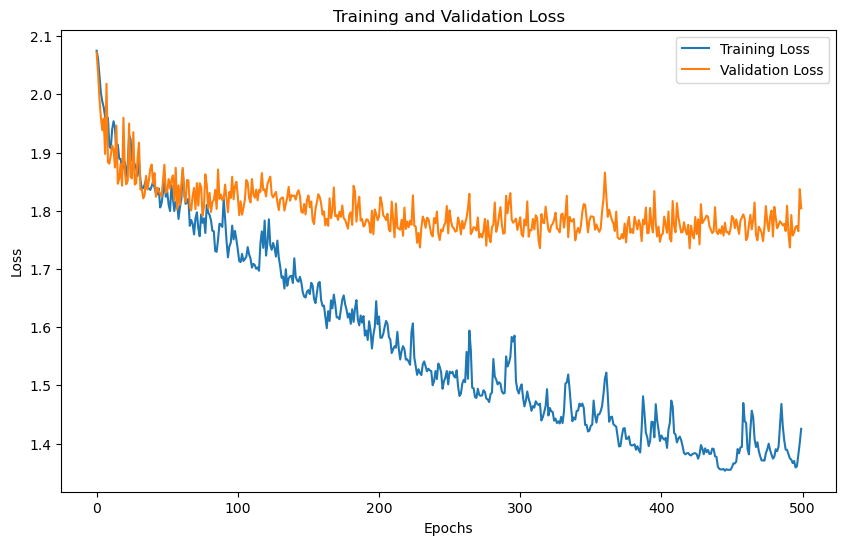

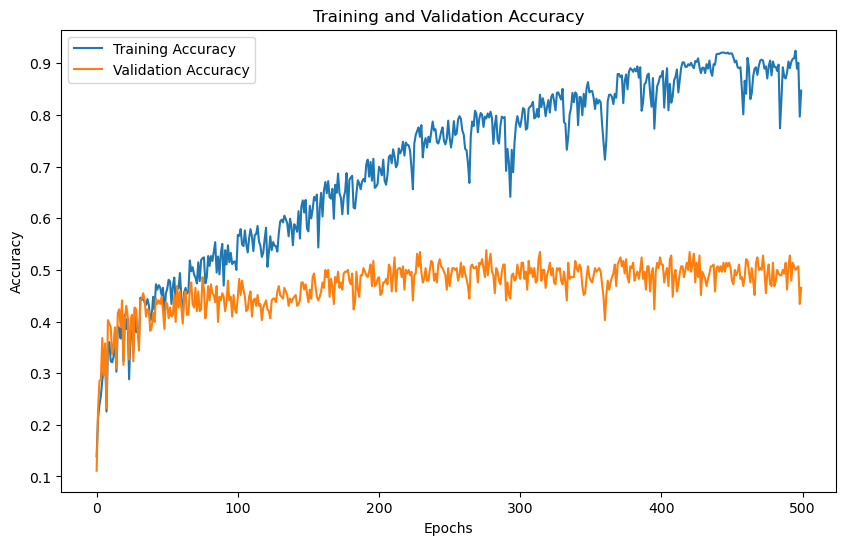

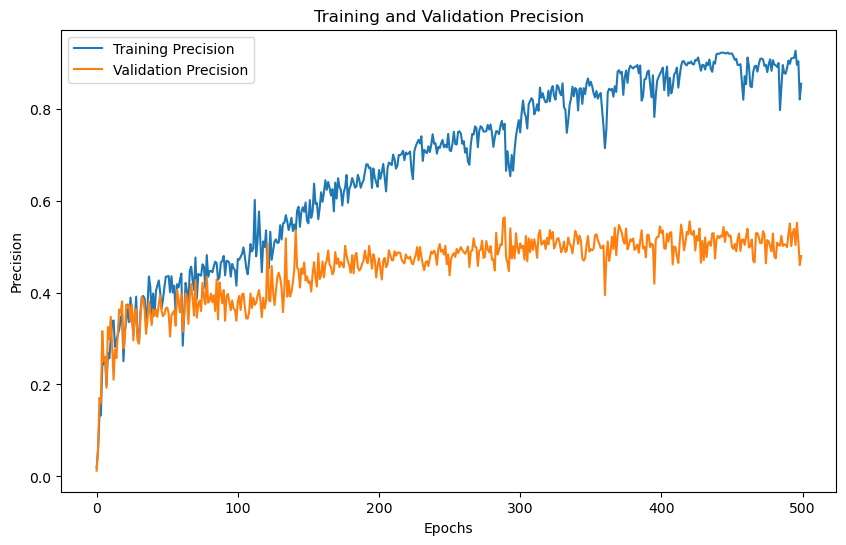

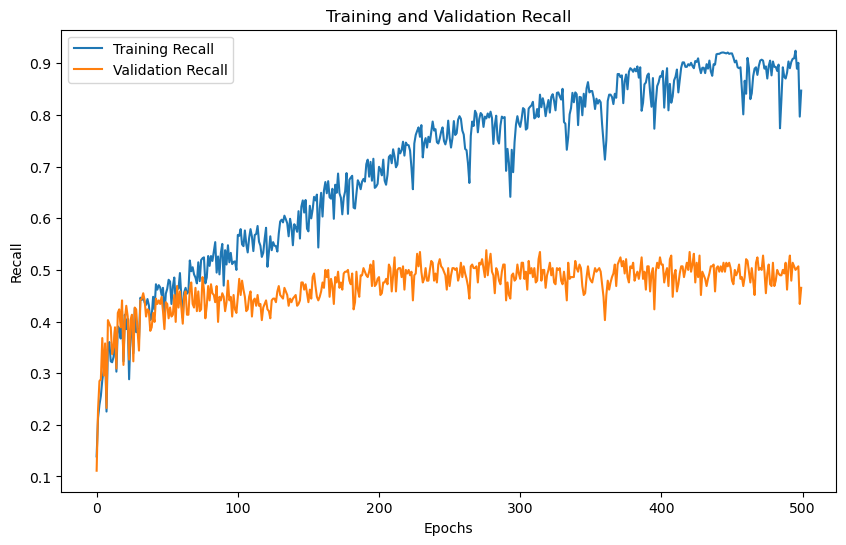

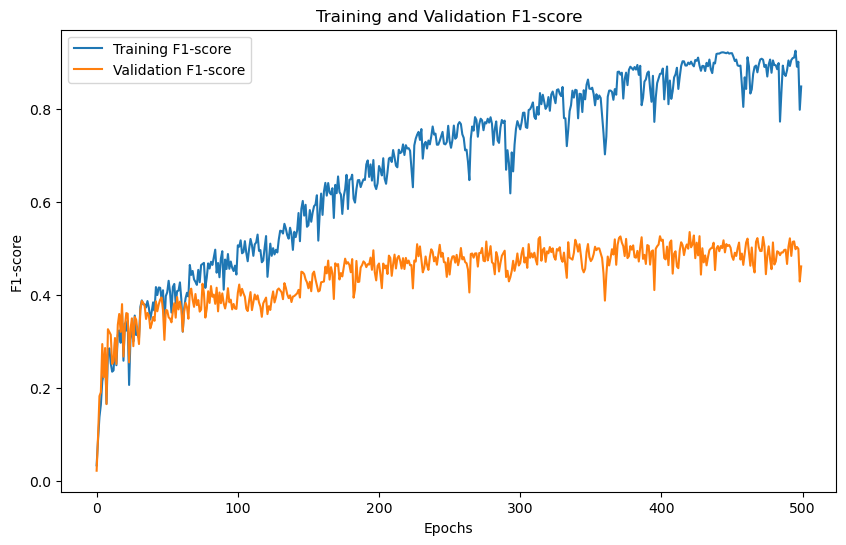

'Model Training and Evaluation Successfully completed'

In [32]:
train_model()

# Crema
# dwt level 4
# nmfcc 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  4
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 4 = 200
Training with DWT level: 4
Input Size : 200
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (7442, 1, 200)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.6790, Training Accuracy: 0.3689, Training Precision:0.2418,Training Recall:0.3689,Training F1-Score:0.2779
Validation Loss: 1.6499, Validation Accuracy: 0.3653, Validation Precision:0.2423,Validation Recall:0.3653,Validation F1-Score:0.2764
Epoch [2/500],
Training Loss: 1.6748, Training Accuracy: 0.3768, Training Precision:0.2837,Training Recall:0.3768,Training F1-Score:0.2959
Validation Loss: 1.6464, Validation Accuracy: 0.3680, Validation Precision:0.2783,Validation Recall:0.3680,Validation F1-Score:0.2845
Epoch [3/500],
Training Loss: 1.6490, Training Accuracy: 0.3497, Training Precision:0.3005,Training Recall:0.3497,Training F1-

Epoch [30/500],
Training Loss: 1.6171, Training Accuracy: 0.4220, Training Precision:0.5376,Training Recall:0.4220,Training F1-Score:0.3544
Validation Loss: 1.6004, Validation Accuracy: 0.4291, Validation Precision:0.5214,Validation Recall:0.4291,Validation F1-Score:0.3606
Epoch [31/500],
Training Loss: 1.5953, Training Accuracy: 0.3691, Training Precision:0.4058,Training Recall:0.3691,Training F1-Score:0.3389
Validation Loss: 1.6601, Validation Accuracy: 0.3533, Validation Precision:0.3942,Validation Recall:0.3533,Validation F1-Score:0.3249
Epoch [32/500],
Training Loss: 1.7060, Training Accuracy: 0.3492, Training Precision:0.2353,Training Recall:0.3492,Training F1-Score:0.2794
Validation Loss: 1.6951, Validation Accuracy: 0.3318, Validation Precision:0.2181,Validation Recall:0.3318,Validation F1-Score:0.2606
Epoch [33/500],
Training Loss: 1.6742, Training Accuracy: 0.3689, Training Precision:0.2912,Training Recall:0.3689,Training F1-Score:0.3217
Validation Loss: 1.6665, Validation Ac

Epoch [60/500],
Training Loss: 1.5650, Training Accuracy: 0.4744, Training Precision:0.4901,Training Recall:0.4744,Training F1-Score:0.4234
Validation Loss: 1.5808, Validation Accuracy: 0.4614, Validation Precision:0.4731,Validation Recall:0.4614,Validation F1-Score:0.4116
Epoch [61/500],
Training Loss: 1.5541, Training Accuracy: 0.4898, Training Precision:0.5077,Training Recall:0.4898,Training F1-Score:0.4587
Validation Loss: 1.5834, Validation Accuracy: 0.4439, Validation Precision:0.4579,Validation Recall:0.4439,Validation F1-Score:0.4100
Epoch [62/500],
Training Loss: 1.5472, Training Accuracy: 0.4952, Training Precision:0.5133,Training Recall:0.4952,Training F1-Score:0.4635
Validation Loss: 1.5729, Validation Accuracy: 0.4607, Validation Precision:0.4730,Validation Recall:0.4607,Validation F1-Score:0.4300
Epoch [63/500],
Training Loss: 1.5482, Training Accuracy: 0.4737, Training Precision:0.4738,Training Recall:0.4737,Training F1-Score:0.4683
Validation Loss: 1.5831, Validation Ac

Epoch [90/500],
Training Loss: 1.5616, Training Accuracy: 0.4668, Training Precision:0.4827,Training Recall:0.4668,Training F1-Score:0.4355
Validation Loss: 1.5933, Validation Accuracy: 0.4365, Validation Precision:0.4311,Validation Recall:0.4365,Validation F1-Score:0.3987
Epoch [91/500],
Training Loss: 1.5784, Training Accuracy: 0.4856, Training Precision:0.4825,Training Recall:0.4856,Training F1-Score:0.4500
Validation Loss: 1.5747, Validation Accuracy: 0.4607, Validation Precision:0.4415,Validation Recall:0.4607,Validation F1-Score:0.4215
Epoch [92/500],
Training Loss: 1.5567, Training Accuracy: 0.4651, Training Precision:0.4623,Training Recall:0.4651,Training F1-Score:0.4169
Validation Loss: 1.5946, Validation Accuracy: 0.4338, Validation Precision:0.4124,Validation Recall:0.4338,Validation F1-Score:0.3814
Epoch [93/500],
Training Loss: 1.5575, Training Accuracy: 0.4920, Training Precision:0.5197,Training Recall:0.4920,Training F1-Score:0.4395
Validation Loss: 1.5714, Validation Ac

Epoch [120/500],
Training Loss: 1.5545, Training Accuracy: 0.4690, Training Precision:0.5065,Training Recall:0.4690,Training F1-Score:0.4161
Validation Loss: 1.5970, Validation Accuracy: 0.4466, Validation Precision:0.4439,Validation Recall:0.4466,Validation F1-Score:0.3837
Epoch [121/500],
Training Loss: 1.5279, Training Accuracy: 0.5288, Training Precision:0.5489,Training Recall:0.5288,Training F1-Score:0.5212
Validation Loss: 1.5746, Validation Accuracy: 0.4607, Validation Precision:0.4610,Validation Recall:0.4607,Validation F1-Score:0.4495
Epoch [122/500],
Training Loss: 1.5208, Training Accuracy: 0.5347, Training Precision:0.5512,Training Recall:0.5347,Training F1-Score:0.5152
Validation Loss: 1.5746, Validation Accuracy: 0.4641, Validation Precision:0.4641,Validation Recall:0.4641,Validation F1-Score:0.4418
Epoch [123/500],
Training Loss: 1.5162, Training Accuracy: 0.5315, Training Precision:0.5331,Training Recall:0.5315,Training F1-Score:0.5239
Validation Loss: 1.5706, Validatio

...

Epoch [360/500],
Training Loss: 1.3867, Training Accuracy: 0.6407, Training Precision:0.6513,Training Recall:0.6407,Training F1-Score:0.6373
Validation Loss: 1.5591, Validation Accuracy: 0.4788, Validation Precision:0.4738,Validation Recall:0.4788,Validation F1-Score:0.4679
Epoch [361/500],
Training Loss: 1.3993, Training Accuracy: 0.6385, Training Precision:0.6453,Training Recall:0.6385,Training F1-Score:0.6380
Validation Loss: 1.5799, Validation Accuracy: 0.4607, Validation Precision:0.4630,Validation Recall:0.4607,Validation F1-Score:0.4584
Epoch [362/500],
Training Loss: 1.3939, Training Accuracy: 0.6493, Training Precision:0.6506,Training Recall:0.6493,Training F1-Score:0.6459
Validation Loss: 1.5594, Validation Accuracy: 0.4815, Validation Precision:0.4707,Validation Recall:0.4815,Validation F1-Score:0.4731
Epoch [363/500],
Training Loss: 1.3986, Training Accuracy: 0.6533, Training Precision:0.6572,Training Recall:0.6533,Training F1-Score:0.6526
Validation Loss: 1.5749, Validatio

Epoch [390/500],
Training Loss: 1.6544, Training Accuracy: 0.4013, Training Precision:0.5331,Training Recall:0.4013,Training F1-Score:0.3143
Validation Loss: 1.6613, Validation Accuracy: 0.3815, Validation Precision:0.2616,Validation Recall:0.3815,Validation F1-Score:0.2877
Epoch [391/500],
Training Loss: 1.6094, Training Accuracy: 0.4393, Training Precision:0.4605,Training Recall:0.4393,Training F1-Score:0.3573
Validation Loss: 1.6392, Validation Accuracy: 0.4009, Validation Precision:0.2652,Validation Recall:0.4009,Validation F1-Score:0.3125
Epoch [392/500],
Training Loss: 1.6045, Training Accuracy: 0.4556, Training Precision:0.4587,Training Recall:0.4556,Training F1-Score:0.3855
Validation Loss: 1.6324, Validation Accuracy: 0.4090, Validation Precision:0.3466,Validation Recall:0.4090,Validation F1-Score:0.3346
Epoch [393/500],
Training Loss: 1.5802, Training Accuracy: 0.4767, Training Precision:0.4995,Training Recall:0.4767,Training F1-Score:0.4342
Validation Loss: 1.6073, Validatio

Epoch [420/500],
Training Loss: 1.5992, Training Accuracy: 0.4704, Training Precision:0.4477,Training Recall:0.4704,Training F1-Score:0.4143
Validation Loss: 1.6437, Validation Accuracy: 0.3976, Validation Precision:0.3278,Validation Recall:0.3976,Validation F1-Score:0.3373
Epoch [421/500],
Training Loss: 1.5470, Training Accuracy: 0.5013, Training Precision:0.5338,Training Recall:0.5013,Training F1-Score:0.4582
Validation Loss: 1.6293, Validation Accuracy: 0.4077, Validation Precision:0.4397,Validation Recall:0.4077,Validation F1-Score:0.3654
Epoch [422/500],
Training Loss: 1.5359, Training Accuracy: 0.5466, Training Precision:0.5621,Training Recall:0.5466,Training F1-Score:0.5299
Validation Loss: 1.6158, Validation Accuracy: 0.4224, Validation Precision:0.4559,Validation Recall:0.4224,Validation F1-Score:0.4091
Epoch [423/500],
Training Loss: 1.4710, Training Accuracy: 0.5962, Training Precision:0.6214,Training Recall:0.5962,Training F1-Score:0.5911
Validation Loss: 1.5768, Validatio

Epoch [450/500],
Training Loss: 1.3829, Training Accuracy: 0.6541, Training Precision:0.6685,Training Recall:0.6541,Training F1-Score:0.6461
Validation Loss: 1.5494, Validation Accuracy: 0.4903, Validation Precision:0.4866,Validation Recall:0.4903,Validation F1-Score:0.4744
Epoch [451/500],
Training Loss: 1.4031, Training Accuracy: 0.6447, Training Precision:0.6505,Training Recall:0.6447,Training F1-Score:0.6426
Validation Loss: 1.5693, Validation Accuracy: 0.4674, Validation Precision:0.4809,Validation Recall:0.4674,Validation F1-Score:0.4680
Epoch [452/500],
Training Loss: 1.4056, Training Accuracy: 0.6655, Training Precision:0.6738,Training Recall:0.6655,Training F1-Score:0.6634
Validation Loss: 1.5562, Validation Accuracy: 0.4768, Validation Precision:0.4790,Validation Recall:0.4768,Validation F1-Score:0.4723
Epoch [453/500],
Training Loss: 1.3847, Training Accuracy: 0.6588, Training Precision:0.6752,Training Recall:0.6588,Training F1-Score:0.6569
Validation Loss: 1.5532, Validatio

Epoch [480/500],
Training Loss: 1.4421, Training Accuracy: 0.5980, Training Precision:0.5984,Training Recall:0.5980,Training F1-Score:0.5923
Validation Loss: 1.5814, Validation Accuracy: 0.4587, Validation Precision:0.4527,Validation Recall:0.4587,Validation F1-Score:0.4502
Epoch [481/500],
Training Loss: 1.4446, Training Accuracy: 0.6167, Training Precision:0.6206,Training Recall:0.6167,Training F1-Score:0.6120
Validation Loss: 1.5690, Validation Accuracy: 0.4668, Validation Precision:0.4559,Validation Recall:0.4668,Validation F1-Score:0.4560
Epoch [482/500],
Training Loss: 1.4248, Training Accuracy: 0.6098, Training Precision:0.6286,Training Recall:0.6098,Training F1-Score:0.6087
Validation Loss: 1.5744, Validation Accuracy: 0.4641, Validation Precision:0.4710,Validation Recall:0.4641,Validation F1-Score:0.4576
Epoch [483/500],
Training Loss: 1.5696, Training Accuracy: 0.5110, Training Precision:0.5356,Training Recall:0.5110,Training F1-Score:0.4938
Validation Loss: 1.5976, Validatio

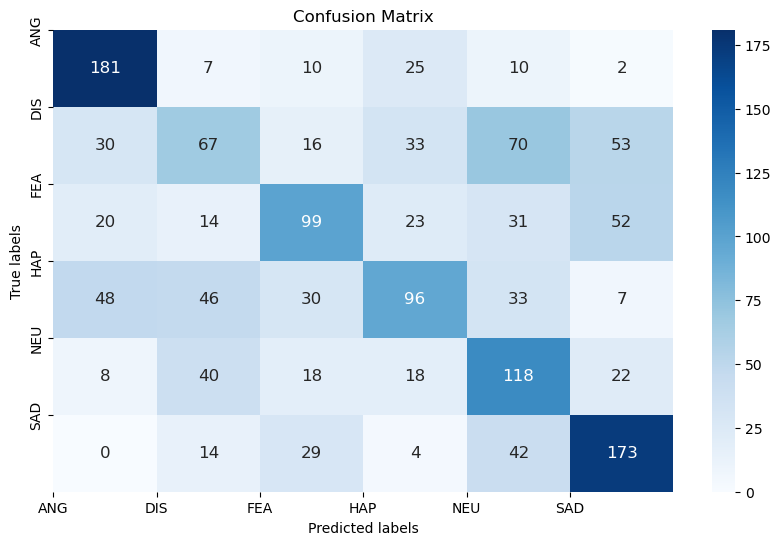

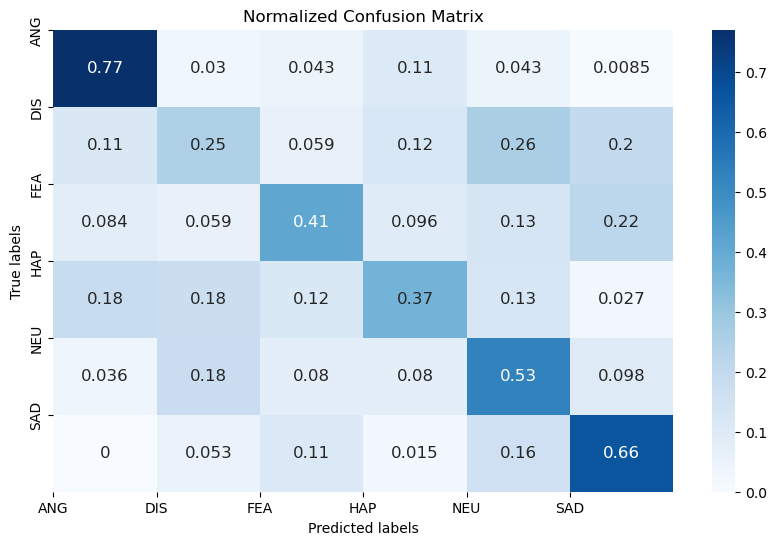

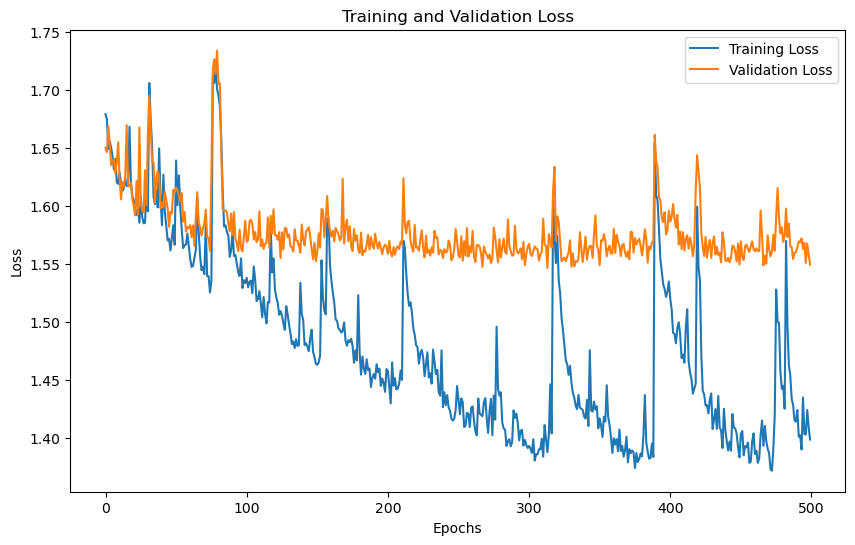

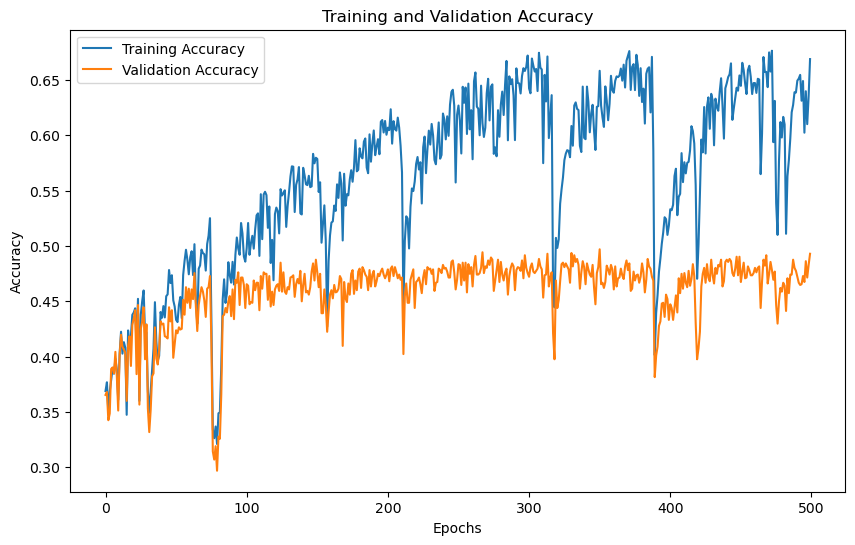

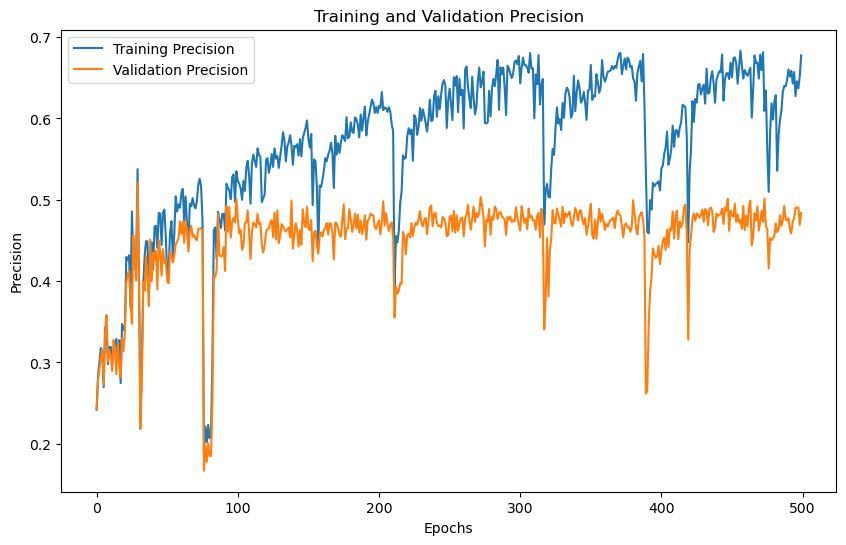

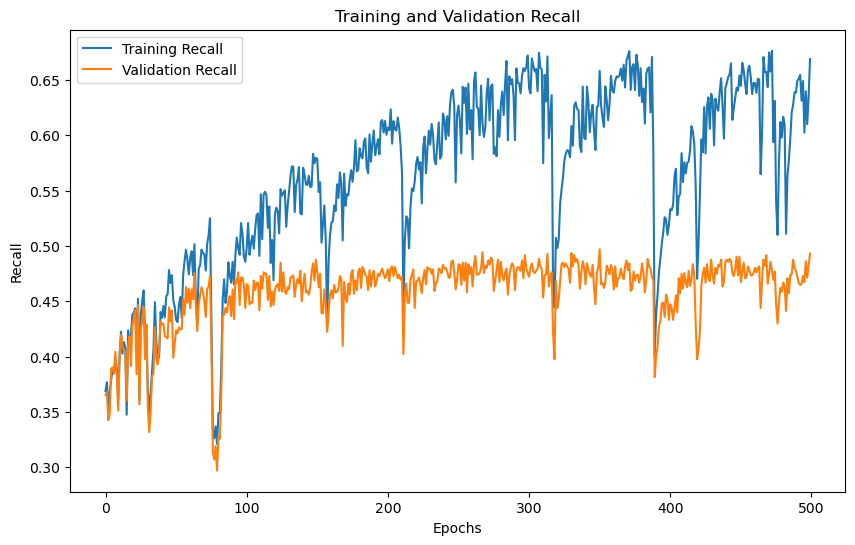

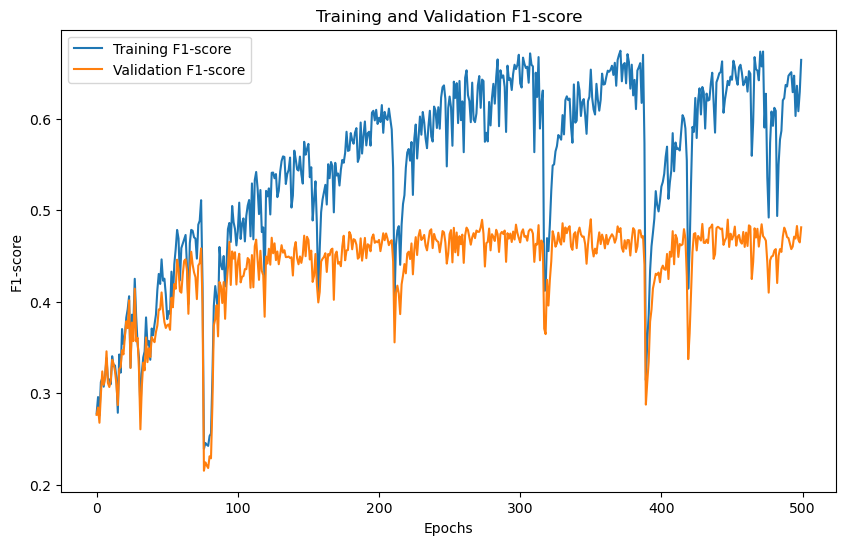

'Model Training and Evaluation Successfully completed'

In [33]:
train_model()

# crema
# dwt level 3
# nmfcc 16

# 500 epochs

In [ ]:
train_model()

# 500 epochs

In [ ]:
train_model()

# RAVDESS

# dwt 1

# 500 epochs

In [ ]:
train_model()

# dwt 2

# 500 epochs

In [ ]:
train_model()

# dwt 3

# 500 epochs

In [ ]:
train_model()

# dwt 4

# 500 epochs

In [ ]:
train_model()

# dwt 5

# 500 epochs

In [ ]:
train_model()

# crema

# dwt 1

# 500 epochs

In [ ]:
train_model()

# dwt 2
# 500 epochs

In [ ]:
train_model()

# dwt 3

# 500 epochs

In [ ]:
train_model()

# dwt 4

# 500 epochs

In [ ]:
train_model()

# dwt 5

# 500 epochs

In [ ]:
train_model()

# TESS

# dwt 1

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 7
Input size for wavelet level 1 = 80
Training with DWT level: 1
Input Size : 80
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (2800, 1, 80)
Y Shape : (2800, 7)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.7913, Training Accuracy: 0.6763, Training Precision:0.5322,Training Recall:0.6763,Training F1-Score:0.5823
Validation Loss: 1.5613, Validation Accuracy: 0.6625, Validation Precision:0.5266,Validation Recall:0.6625,Validation F1-Score:0.5704
Epoch [2/200],
Training Loss: 1.4977, Training Accuracy: 0.6696, Training Precision:0.5122,Training Recall:0.6696,Training F1-Score:0.5706
Validation Loss: 1.5010, Validation Accuracy: 0.6554, Validation Precision:0.4916,Validation Recall:0.6554,Validation F1-Score:0.5523
Epoch [3/200],
Training Loss: 1.4209, Training Accuracy: 0.8143, Training Precision:0.7135,Training Recall:0.8143,Training F1-Scor

Epoch [30/200],
Training Loss: 1.1737, Training Accuracy: 0.9915, Training Precision:0.9916,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 1.1827, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [31/200],
Training Loss: 1.1742, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1751, Validation Accuracy: 0.9911, Validation Precision:0.9911,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [32/200],
Training Loss: 1.1763, Training Accuracy: 0.9875, Training Precision:0.9879,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 1.1827, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [33/200],
Training Loss: 1.1754, Training Accuracy: 0.9924, Training Precision:0.9926,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1779, Validation Ac

Epoch [60/200],
Training Loss: 1.1882, Training Accuracy: 0.9741, Training Precision:0.9753,Training Recall:0.9741,Training F1-Score:0.9741
Validation Loss: 1.1987, Validation Accuracy: 0.9696, Validation Precision:0.9713,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [61/200],
Training Loss: 1.1814, Training Accuracy: 0.9862, Training Precision:0.9865,Training Recall:0.9862,Training F1-Score:0.9861
Validation Loss: 1.1861, Validation Accuracy: 0.9786, Validation Precision:0.9792,Validation Recall:0.9786,Validation F1-Score:0.9784
Epoch [62/200],
Training Loss: 1.1772, Training Accuracy: 0.9790, Training Precision:0.9807,Training Recall:0.9790,Training F1-Score:0.9791
Validation Loss: 1.1920, Validation Accuracy: 0.9714, Validation Precision:0.9735,Validation Recall:0.9714,Validation F1-Score:0.9714
Epoch [63/200],
Training Loss: 1.1747, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1756, Validation Ac

Epoch [90/200],
Training Loss: 1.1847, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 1.1861, Validation Accuracy: 0.9786, Validation Precision:0.9792,Validation Recall:0.9786,Validation F1-Score:0.9784
Epoch [91/200],
Training Loss: 1.1846, Training Accuracy: 0.9754, Training Precision:0.9767,Training Recall:0.9754,Training F1-Score:0.9751
Validation Loss: 1.2082, Validation Accuracy: 0.9571, Validation Precision:0.9603,Validation Recall:0.9571,Validation F1-Score:0.9566
Epoch [92/200],
Training Loss: 1.1766, Training Accuracy: 0.9862, Training Precision:0.9867,Training Recall:0.9862,Training F1-Score:0.9861
Validation Loss: 1.1923, Validation Accuracy: 0.9732, Validation Precision:0.9737,Validation Recall:0.9732,Validation F1-Score:0.9731
Epoch [93/200],
Training Loss: 1.1767, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 1.1829, Validation Ac

Epoch [120/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1771, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [121/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1771, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [122/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1771, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [123/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1770, Validatio

Epoch [150/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1766, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [151/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1766, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [152/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1766, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [153/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1766, Validatio

Epoch [180/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9892
Epoch [181/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9892
Epoch [182/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9892
Epoch [183/200],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1762, Validatio

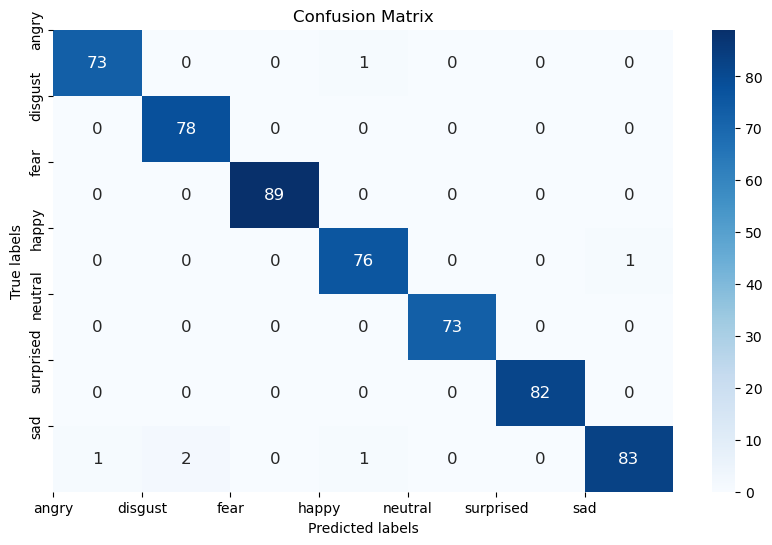

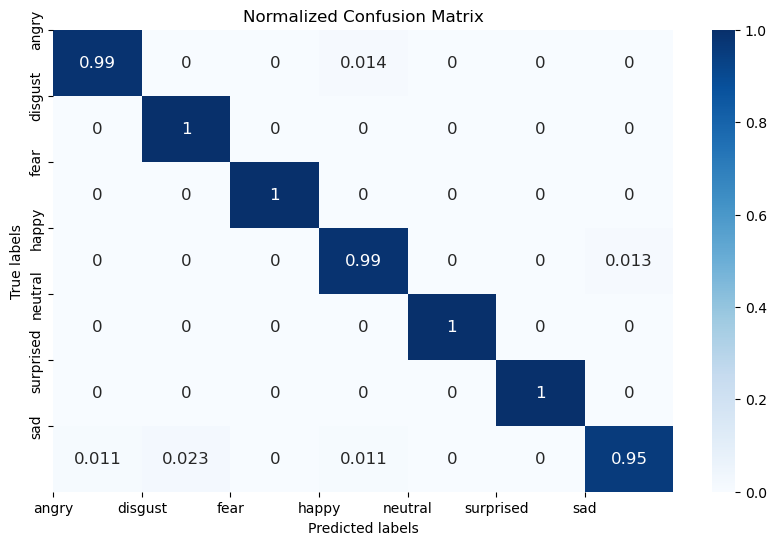

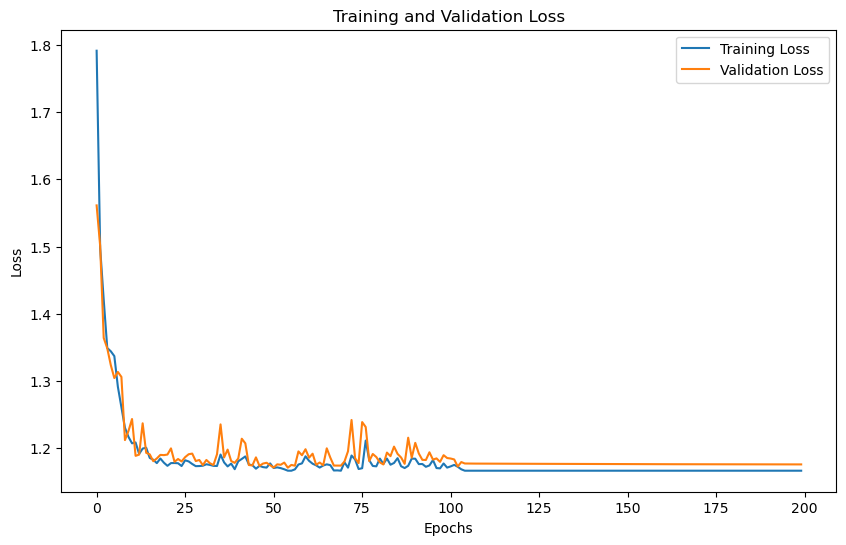

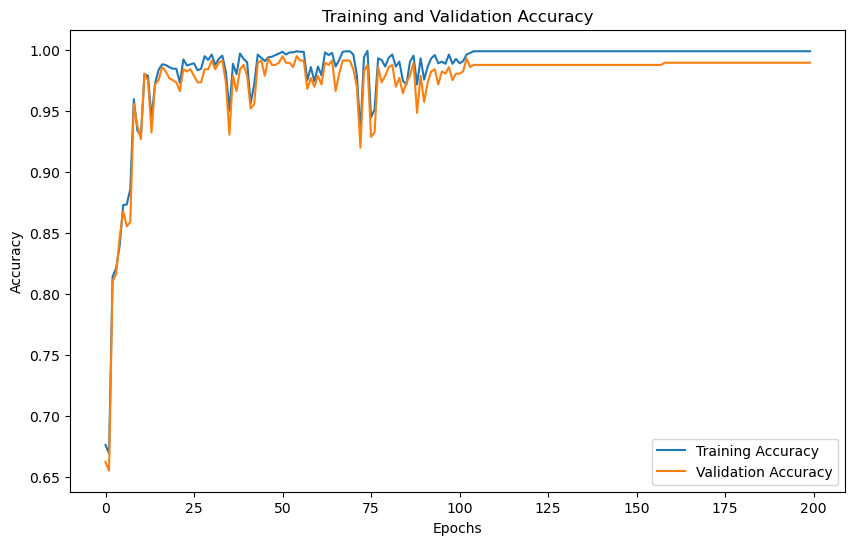

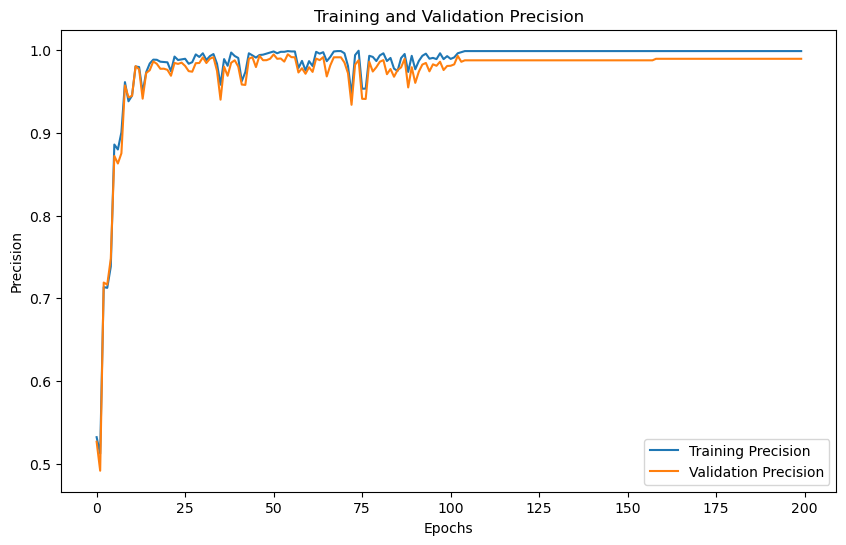

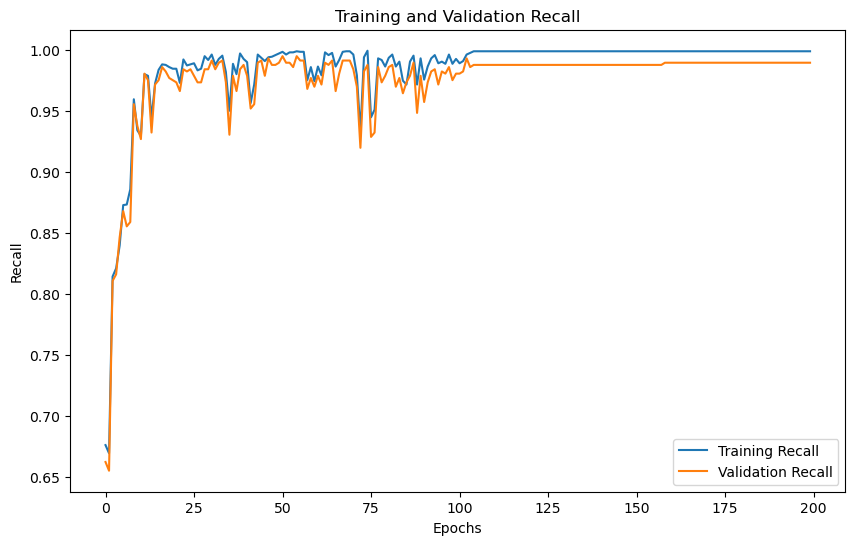

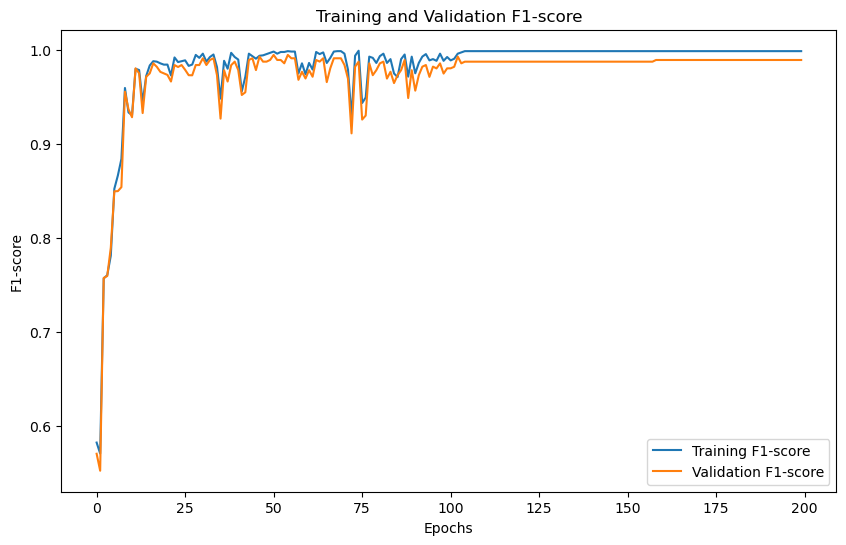

'Model Training and Evaluation Successfully completed'

In [28]:
train_model()

# dwt 2

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  2
Enter Number of MFCC coefficients : 40
No. of classes 7
Input size for wavelet level 2 = 120
Training with DWT level: 2
Input Size : 120
Hidden Size : 256
Model Name: Conv3LSTMModel

X Shape : (2800, 1, 120)
Y Shape : (2800, 7)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.7484, Training Accuracy: 0.6915, Training Precision:0.6281,Training Recall:0.6915,Training F1-Score:0.6381
Validation Loss: 1.5230, Validation Accuracy: 0.6804, Validation Precision:0.6016,Validation Recall:0.6804,Validation F1-Score:0.6210
Epoch [2/200],
Training Loss: 1.4066, Training Accuracy: 0.8746, Training Precision:0.8864,Training Recall:0.8746,Training F1-Score:0.8633
Validation Loss: 1.3006, Validation Accuracy: 0.8821, Validation Precision:0.8975,Validation Recall:0.8821,Validation F1-Score:0.8710
Epoch [3/200],
Training Loss: 1.2442, Training Accuracy: 0.9750, Training Precision:0.9750,Training Recall:0.9750,Training F1-S

Epoch [30/200],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1694, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [31/200],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1694, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [32/200],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1694, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [33/200],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1694, Validation Ac

Epoch [60/200],
Training Loss: 1.1779, Training Accuracy: 0.9893, Training Precision:0.9895,Training Recall:0.9893,Training F1-Score:0.9892
Validation Loss: 1.1841, Validation Accuracy: 0.9821, Validation Precision:0.9826,Validation Recall:0.9821,Validation F1-Score:0.9820
Epoch [61/200],
Training Loss: 1.1838, Training Accuracy: 0.9929, Training Precision:0.9930,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 1.1792, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [62/200],
Training Loss: 1.1821, Training Accuracy: 0.9777, Training Precision:0.9785,Training Recall:0.9777,Training F1-Score:0.9773
Validation Loss: 1.1948, Validation Accuracy: 0.9714, Validation Precision:0.9728,Validation Recall:0.9714,Validation F1-Score:0.9710
Epoch [63/200],
Training Loss: 1.1856, Training Accuracy: 0.9893, Training Precision:0.9897,Training Recall:0.9893,Training F1-Score:0.9893
Validation Loss: 1.1749, Validation Ac

Epoch [90/200],
Training Loss: 1.1780, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1744, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [91/200],
Training Loss: 1.1810, Training Accuracy: 0.9915, Training Precision:0.9917,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 1.1736, Validation Accuracy: 0.9911, Validation Precision:0.9914,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [92/200],
Training Loss: 1.1721, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1683, Validation Accuracy: 0.9982, Validation Precision:0.9982,Validation Recall:0.9982,Validation F1-Score:0.9982
Epoch [93/200],
Training Loss: 1.1672, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1712, Validation Ac

Epoch [120/200],
Training Loss: 1.1779, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1800, Validation Accuracy: 0.9857, Validation Precision:0.9862,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [121/200],
Training Loss: 1.1778, Training Accuracy: 0.9946, Training Precision:0.9948,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1797, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [122/200],
Training Loss: 1.1804, Training Accuracy: 0.9817, Training Precision:0.9821,Training Recall:0.9817,Training F1-Score:0.9817
Validation Loss: 1.2016, Validation Accuracy: 0.9643, Validation Precision:0.9655,Validation Recall:0.9643,Validation F1-Score:0.9641
Epoch [123/200],
Training Loss: 1.2042, Training Accuracy: 0.9924, Training Precision:0.9926,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1822, Validatio

Epoch [150/200],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1743, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [151/200],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1743, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [152/200],
Training Loss: 1.1677, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1741, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [153/200],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1744, Validatio

Epoch [180/200],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1708, Validation Accuracy: 0.9946, Validation Precision:0.9946,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [181/200],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1708, Validation Accuracy: 0.9946, Validation Precision:0.9946,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [182/200],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1708, Validation Accuracy: 0.9946, Validation Precision:0.9946,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [183/200],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1708, Validatio

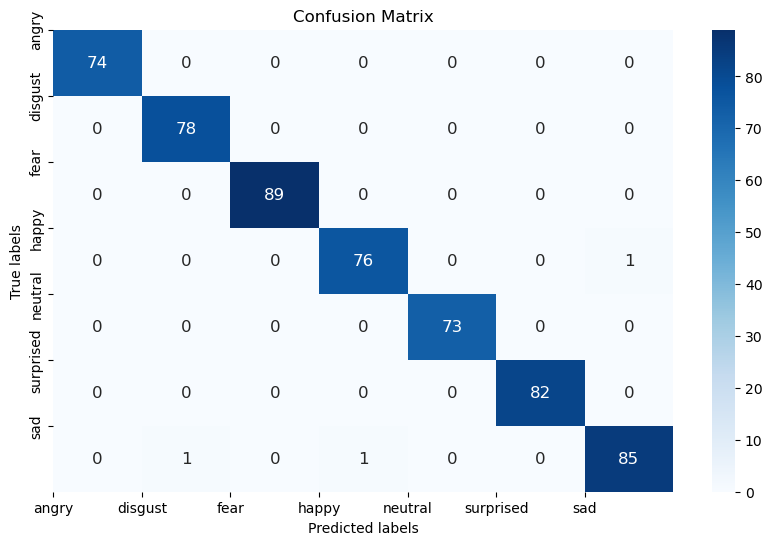

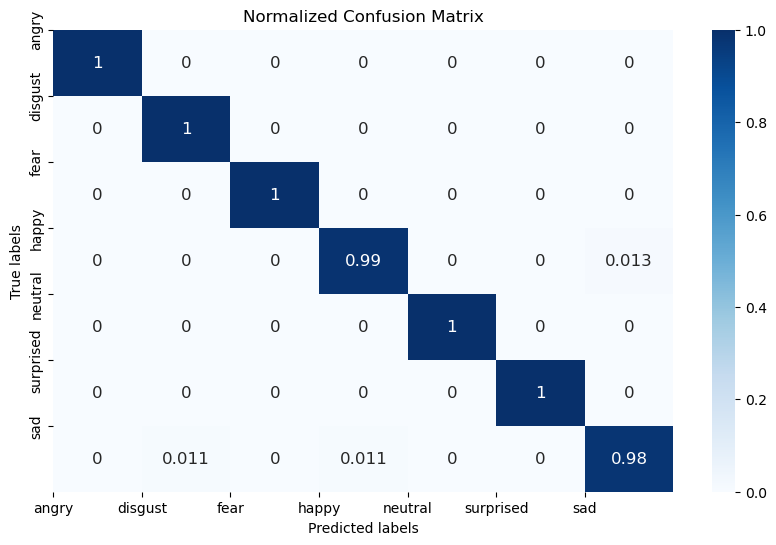

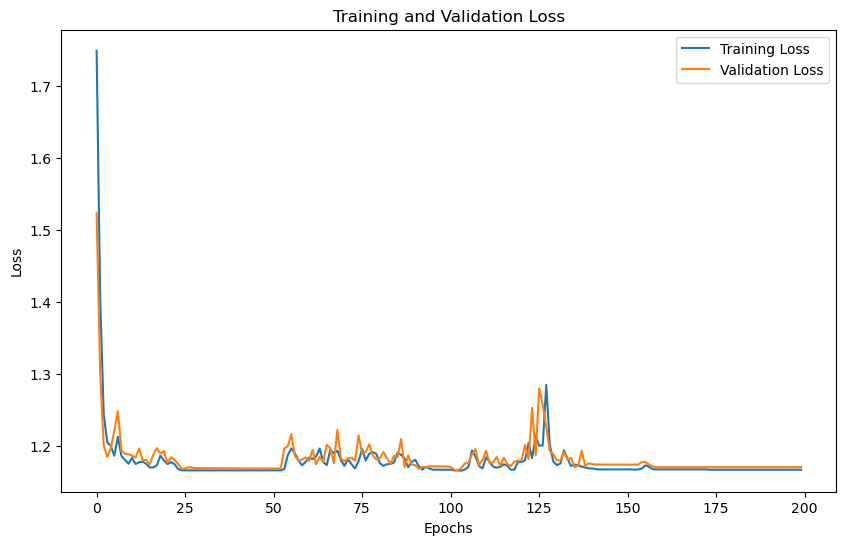

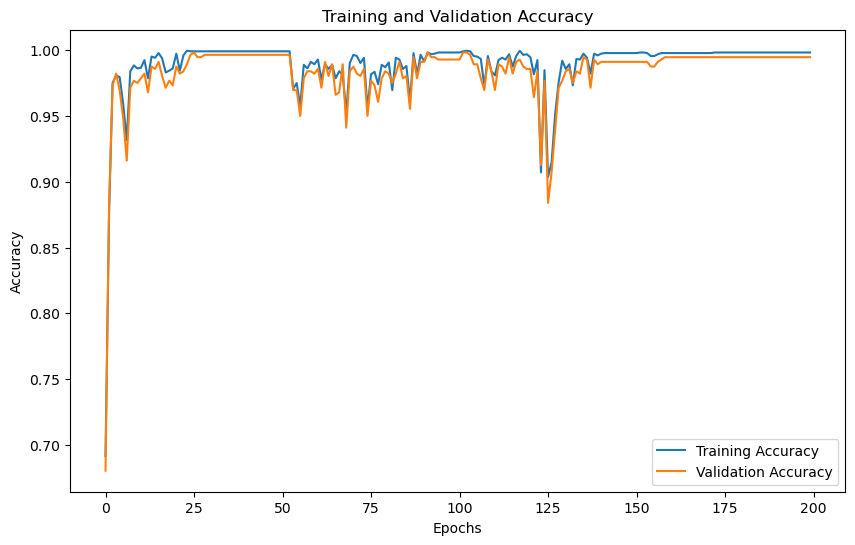

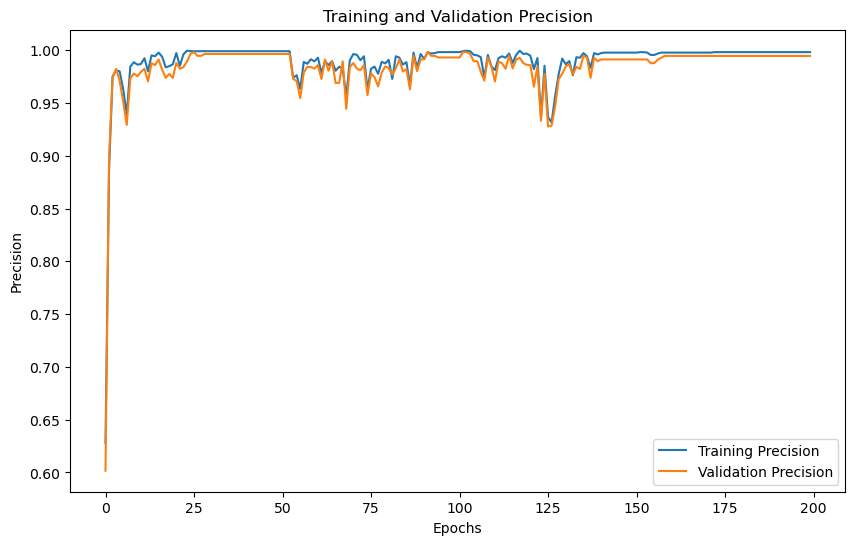

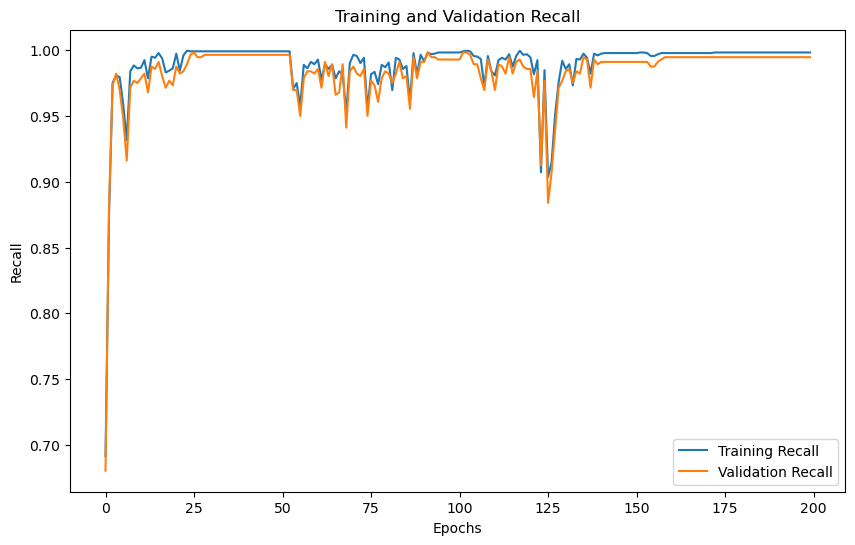

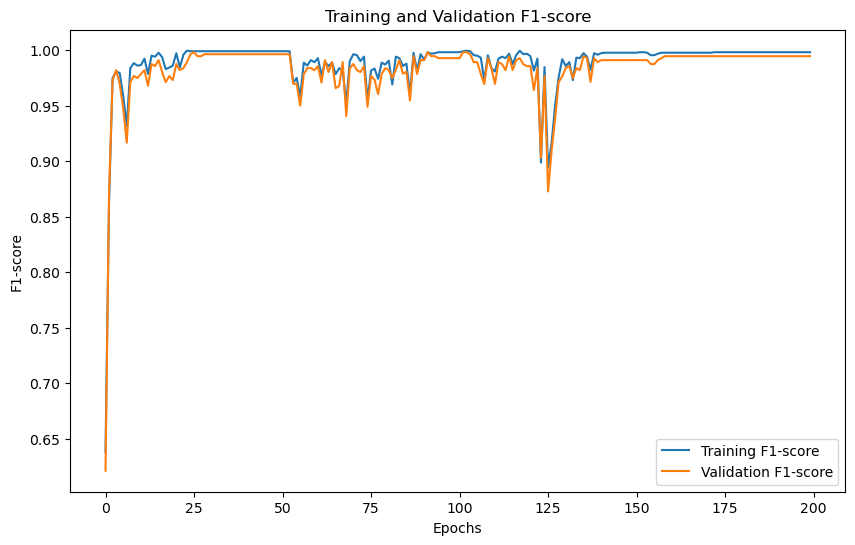

'Model Training and Evaluation Successfully completed'

In [29]:
train_model()

# dwt 3

# 500 epoch

In [ ]:
train_model()

# dwt 4

# 500 epoch

In [ ]:
train_model()

# dwt 5

# 500 epoch

In [ ]:
train_model()